In [1]:
import argparse
from rclpy.serialization import deserialize_message
from rosidl_runtime_py.utilities import get_message
from std_msgs.msg import String
from geometry_msgs.msg import PoseStamped
import rosbag2_py
import numpy as np
import matplotlib.pyplot as plt
import motor_msgs

/home/devuser/retail-bot/.venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
def get_metadata(input_bag: str):
    reader = rosbag2_py.SequentialReader()
    reader.open(
        rosbag2_py.StorageOptions(uri=input_bag, storage_id="mcap"),
        rosbag2_py.ConverterOptions(
            input_serialization_format="cdr", output_serialization_format="cdr"
        ),
    )
    return reader.get_metadata()

def read_messages(input_bag: str):
    reader = rosbag2_py.SequentialReader()
    reader.open(
        rosbag2_py.StorageOptions(uri=input_bag, storage_id="mcap"),
        rosbag2_py.ConverterOptions(
            input_serialization_format="cdr", output_serialization_format="cdr"
        ),
    )
    print(reader.get_metadata())

    topic_types = reader.get_all_topics_and_types()

    def typename(topic_name):
        for topic_type in topic_types:
            if topic_type.name == topic_name:
                return topic_type.type
        raise ValueError(f"topic {topic_name} not in bag")

    while reader.has_next():
        topic, data, timestamp = reader.read_next()
        msg_type = get_message(typename(topic))
        msg = deserialize_message(data, msg_type)
        yield topic, msg, timestamp
    del reader

In [3]:
bag_path = "../../../2025_2_20_rosbags-20250228T132944Z-001/2025_2_20_rosbags/2025_02_20__15_45_30_arc_drive_Arclength10_ArcVel5.bag/2025_02_20__15_45_30_arc_drive_Arclength10_ArcVel5.bag_0.mcap"
metadata = get_metadata(bag_path)
# metadata.topics_with_message_count[2].message_count

# Use this to find out topics and their message counts. 
topics = {name.topic_metadata.name : name.message_count for name in metadata.topics_with_message_count}
print(topics)

{'/vrpn_mocap/rb1/twist': 4728, '/vrpn_mocap/rb1/pose': 4728, '/vrpn_mocap/rb1/accel': 4728, '/dynamic_joint_states': 656, '/rb_slip_controller/transition_event': 0, '/joint_state_broadcaster/transition_event': 0, '/joint_states': 656, '/rb_slip_controller/odom': 655, '/rosout': 705, '/tf_static': 2, '/odom_in_vicon_frame': 0, '/parameter_events': 0, '/events/write_split': 0, '/rb/cmd_vel': 0, '/rb_slip_controller/cmd_vel': 124, '/joy': 376, '/left_motor_currents': 3993, '/pico_imu': 3097, '/right_motor_currents': 3915, '/tf': 983, '/robot_description': 1, '/diagnostics': 24}


In [4]:
for topic_info in metadata.topics_with_message_count:
    if topic_info.topic_metadata.name == "/vrpn_mocap/rb1/pose":
        topic_name = topic_info.topic_metadata.name
        message_count = topic_info.message_count
        duration = metadata.duration.nanoseconds * 1e-9  # Convert to seconds
        frequency = message_count / duration if duration > 0 else 0
        print(f"Topic: {topic_name}")
        print(f"Total Messages: {message_count}")
        print(f"Bag Duration: {duration:.2f} seconds")
        print(f"Estimated Frequency: {frequency:.2f} Hz")

Topic: /vrpn_mocap/rb1/pose
Total Messages: 4728
Bag Duration: 24.72 seconds
Estimated Frequency: 191.24 Hz


In [7]:
#bag_path = "../../retail_bot_exp_02_03/2025_2_3__17_25_29drive_stop_1.bag-20250204T151843Z-001/2025_2_3__17_25_29drive_stop_1.bag/2025_2_3__17_25_29drive_stop_1.bag_0.mcap"
topic_name = "/rb_slip_controller/odom"

# Counter to limit the number of messages displayed
count = 0
max_messages = 100  # Change this number if you want more messages

for topic, msg, timestamp in read_messages(bag_path):
    if topic == topic_name:
        print(f"Timestamp: {timestamp}, Message: {msg}")
        count += 1
    if count >= max_messages:
        break



Files:             ../../../2025_3_11_rosbags_correct/2025_3_11__15_34_08RPM60_con.bag/2025_3_11__15_34_08RPM60_con.bag_0.mcap
Bag size:          12.7 MiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          54.412956848s
Start:             Mar 11 2025 19:34:08.792055727 (1741721648.792055727)
End:               Mar 11 2025 19:35:03.205012575 (1741721703.205012575)
Messages:          76119
Topic information: Topic: /vrpn_mocap/rb1/twist | Type: geometry_msgs/msg/TwistStamped | Count: 10681 | Serialization Format: cdr
                   Topic: /vrpn_mocap/rb1/pose | Type: geometry_msgs/msg/PoseStamped | Count: 10681 | Serialization Format: cdr
                   Topic: /vrpn_mocap/rb1/accel | Type: geometry_msgs/msg/AccelStamped | Count: 10683 | Serialization Format: cdr
                   Topic: /pico_imu | Type: sensor_msgs/msg/Imu | Count: 6635 | Serialization Format: cdr
                   Topic: /joy | Type: sensor_msgs/msg/Joy | Count: 732 | Serialization Format: c

In [6]:
topic_name = "/odom_in_vicon_frame"

# Counter to limit the number of messages displayed
count = 0
max_messages = 10  # Change this number if you want more messages

for topic, msg, timestamp in read_messages(bag_path):
    if topic == topic_name:
        print(f"Timestamp: {timestamp}, Message: {msg}")
        count += 1
    if count >= max_messages:
        break


Files:             2025_02_20__13_14_56_drive_straight_AngularV10_Distance4.bag_0.mcap
Bag size:          3.6 MiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          16.648690525s
Start:             Feb 20 2025 18:15:10.158130087 (1740075310.158130087)
End:               Feb 20 2025 18:15:26.806820612 (1740075326.806820612)
Messages:          19921
Topic information: Topic: /joy | Type: sensor_msgs/msg/Joy | Count: 243 | Serialization Format: cdr
                   Topic: /rb_slip_controller/transition_event | Type: lifecycle_msgs/msg/TransitionEvent | Count: 0 | Serialization Format: cdr
                   Topic: /rb/cmd_vel | Type: geometry_msgs/msg/TwistStamped | Count: 0 | Serialization Format: cdr
                   Topic: /rb_slip_controller/odom | Type: nav_msgs/msg/Odometry | Count: 436 | Serialization Format: cdr
                   Topic: /tf_static | Type: tf2_msgs/msg/TFMessage | Count: 2 | Serialization Format: cdr
                   Topic: /left_motor_curr

In [5]:
#bag_path = "../../src/data_analysis/2025_2_3__16_56_14imu_still_10min.bag_0.mcap"

# Extract message counts
num_imu_msgs = topics["/pico_imu"]
num_vicon_msgs = topics["/vrpn_mocap/rb1/pose"]
num_vicon_twist_msgs = topics["/vrpn_mocap/rb1/twist"]
num_odom_msgs = topics["/rb_slip_controller/odom"]
num_encoder_msgs = topics["/dynamic_joint_states"]

# Preallocate arrays for IMU (acceleration + angular velocity)
imu_acc = np.zeros((3, num_imu_msgs))
imu_gyro = np.zeros((3, num_imu_msgs))
imu_timestamps = np.zeros(num_imu_msgs)

# Preallocate arrays for Vicon pose (x, y, z, quaternion [w, x, y, z])
vicon_poses = np.zeros((7, num_vicon_msgs))  # (x, y, z, qw, qx, qy, qz)
vicon_timestamps = np.zeros(num_vicon_msgs)

vicon_twists = np.zeros((6, num_vicon_twist_msgs))
vicon_twist_timestamps = np.zeros(num_vicon_twist_msgs)

# Preallocate arrays for Odometry data
# Pose: position (x, y, z) and orientation (w, x, y, z) -> 7 values
odom_poses = np.zeros((7, num_odom_msgs))
# Twist: linear (x, y, z) and angular (x, y, z) -> 6 values
odom_twists = np.zeros((6, num_odom_msgs))
odom_timestamps = np.zeros(num_odom_msgs)

encoder_counts = np.zeros((4, num_encoder_msgs))
encoder_timestamps = np.zeros(num_encoder_msgs)

# Read messages and store IMU, Vicon, and Odometry data
imu_idx, vicon_idx, odom_idx, vicon_twist_idx, encoder_idx = 0, 0, 0, 0, 0
for topic, msg, timestamp in read_messages(bag_path):
    time_sec = timestamp * 1e-9  # Convert to seconds

    if topic == "/pico_imu":
        imu_acc[:, imu_idx] = [
            msg.linear_acceleration.x,
            msg.linear_acceleration.y,
            msg.linear_acceleration.z,
        ]
        imu_gyro[:, imu_idx] = [
            msg.angular_velocity.x,
            msg.angular_velocity.y,
            msg.angular_velocity.z,
        ]
        imu_timestamps[imu_idx] = time_sec
        imu_idx += 1

    elif topic == "/vrpn_mocap/rb1/pose":
        vicon_poses[:, vicon_idx] = [
            msg.pose.position.x,
            msg.pose.position.y,
            msg.pose.position.z,
            msg.pose.orientation.w,
            msg.pose.orientation.x,
            msg.pose.orientation.y,
            msg.pose.orientation.z,
        ]
        vicon_timestamps[vicon_idx] = time_sec
        vicon_idx += 1
        
    elif topic == "/vrpn_mocap/rb1/twist":
        # Extract linear and angular velocities from the twist message
        vicon_twists[:, vicon_twist_idx] = [
            msg.twist.linear.x,
            msg.twist.linear.y,
            msg.twist.linear.z,
            msg.twist.angular.x,
            msg.twist.angular.y,
            msg.twist.angular.z,
        ]
        vicon_twist_timestamps[vicon_twist_idx] = time_sec
        vicon_twist_idx += 1

    elif topic == "/rb_slip_controller/odom":
        # Assuming the message is of type nav_msgs/Odometry
        odom_poses[:, odom_idx] = [
            msg.pose.pose.position.x,
            msg.pose.pose.position.y,
            msg.pose.pose.position.z,
            msg.pose.pose.orientation.w,
            msg.pose.pose.orientation.x,
            msg.pose.pose.orientation.y,
            msg.pose.pose.orientation.z,
        ]
        odom_twists[:, odom_idx] = [
            msg.twist.twist.linear.x,
            msg.twist.twist.linear.y,
            msg.twist.twist.linear.z,
            msg.twist.twist.angular.x,
            msg.twist.twist.angular.y,
            msg.twist.twist.angular.z,
        ]
        odom_timestamps[odom_idx] = time_sec
        odom_idx += 1
        
    elif topic == "/dynamic_joint_states":
        # Loop over each joint in the message
        for i, interface_val in enumerate(msg.interface_values):
            enc_index = interface_val.interface_names.index("encoder_count")
            encoder_counts[i, encoder_idx] = interface_val.values[enc_index]
        encoder_timestamps[encoder_idx] = time_sec
        encoder_idx += 1
    
# Normalize timestamps to start from zero
imu_timestamps -= imu_timestamps[0]
vicon_timestamps -= vicon_timestamps[0]
vicon_twist_timestamps -= vicon_twist_timestamps[0]
if odom_idx > 0:  # Ensure we have at least one odom message
    odom_timestamps -= odom_timestamps[0]
if encoder_idx > 0:
    encoder_timestamps -= encoder_timestamps[0]

# Save data to .npz file
np.savez(
    "../Sensor_data/2025_02_20__15_45_30_arc_drive_Arclength10_ArcVel5.bag_0.npz",
    imu_acc=imu_acc,
    imu_gyro=imu_gyro,
    imu_timestamps=imu_timestamps,
    vicon_poses=vicon_poses,
    vicon_timestamps=vicon_timestamps,
    vicon_twists=vicon_twists,
    vicon_twist_timestamps=vicon_twist_timestamps,
    odom_poses=odom_poses,
    odom_twists=odom_twists,
    odom_timestamps=odom_timestamps,
    encoder_counts=encoder_counts,
    encoder_timestamps=encoder_timestamps,
)

#print("IMU, Vicon, and Odometry data saved to sensor_data_spin_5rpm.npz")



Files:             ../../../2025_2_20_rosbags-20250228T132944Z-001/2025_2_20_rosbags/2025_02_20__15_45_30_arc_drive_Arclength10_ArcVel5.bag/2025_02_20__15_45_30_arc_drive_Arclength10_ArcVel5.bag_0.mcap
Bag size:          5.2 MiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          24.723172975s
Start:             Feb 20 2025 20:45:35.753559359 (1740084335.753559359)
End:               Feb 20 2025 20:46:00.476732334 (1740084360.476732334)
Messages:          29371
Topic information: Topic: /vrpn_mocap/rb1/twist | Type: geometry_msgs/msg/TwistStamped | Count: 4728 | Serialization Format: cdr
                   Topic: /vrpn_mocap/rb1/pose | Type: geometry_msgs/msg/PoseStamped | Count: 4728 | Serialization Format: cdr
                   Topic: /vrpn_mocap/rb1/accel | Type: geometry_msgs/msg/AccelStamped | Count: 4728 | Serialization Format: cdr
                   Topic: /dynamic_joint_states | Type: control_msgs/msg/DynamicJointState | Count: 656 | Serialization Format: cdr


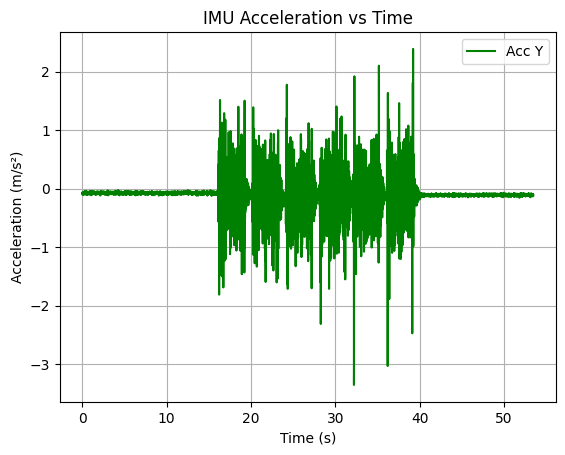

In [6]:
# Plot the IMU accelerations
#plt.figure
#plt.plot(imu_timestamps, imu_acc[0, :], label="Acc X", color='r')
plt.figure
plt.plot(imu_timestamps, imu_acc[1, :], label="Acc Y", color='g')
#plt.figure
#plt.plot(timestamps, imu_acc[2, :], label="Acc Z", color='b')

plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title("IMU Acceleration vs Time")
plt.legend()
plt.grid()
plt.show()


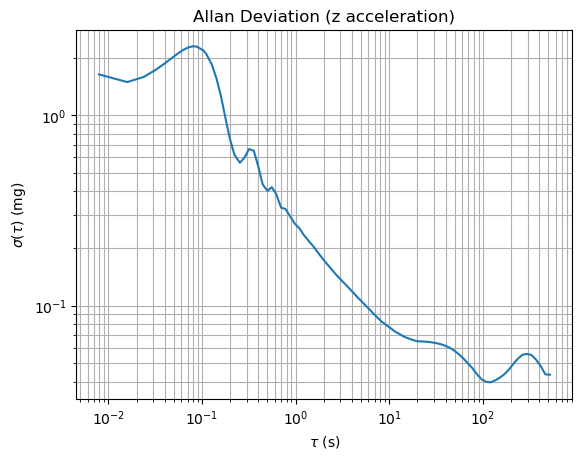

In [38]:
Fs = 126  # Sampling rate in Hz
t0 = 1 / Fs
theta = np.cumsum(imu_acc[2, :]) * t0  # Integrated acceleration

# Allan variance computation
maxNumM = 100
L = len(theta)
maxM = 2 ** int(np.floor(np.log2(L / 2)))
m = np.logspace(np.log10(1), np.log10(maxM), maxNumM).astype(int)
m = np.unique(m)  # Remove duplicates
tau = m * t0
avar = np.zeros(len(m))

for i in range(len(m)):
    mi = m[i]
    avar[i] = np.sum((theta[2 * mi:L] - 2 * theta[mi:L - mi] + theta[:L - 2 * mi]) ** 2)

avar /= (2 * tau ** 2 * (L - 2 * m))
adev = np.sqrt(avar) * 101.971  # Convert from m/s² to mg

# Plotting the results
plt.figure()
plt.loglog(tau, adev)
plt.title('Allan Deviation (z acceleration)')
plt.xlabel(r'$\tau$ (s)')
plt.ylabel(r'$\sigma(\tau)$ (mg)')
plt.grid(True, which='both')
plt.show()

In [16]:
import sqlite3
bagfile1 = "../../logging/2025_2_3_rosbags/2025_2_3__18_00_30sin_drive_0to6RPM.bag/"

conn = sqlite3.connect(bagfile1)
cursor = conn.cursor()

cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = cursor.fetchall()
print(tables)

OperationalError: unable to open database file